In [1]:
import cloudViewer as cv3d
import numpy as np
import re
import os
import sys

# monkey patches visualization and provides helpers to load geometries
sys.path.append('..')
import cloudViewer_tutorial as cv3dtut
# change to True if you want to interact with the visualization windows
cv3dtut.interactive = not "CI" in os.environ
# if running on Travis CI, the number of iterations is reduced
is_ci = "CI" in os.environ

Using external CloudViewer-ML in /root/CloudViewer-ML


# Color Map Optimization
Consider color mapping to the geometry reconstructed from depth cameras. As color and depth frames are not perfectly aligned, the texture mapping using color images is subject to results in blurred color map. CloudViewer provides color map optimization method proposed by [\[Zhou2014\]](../reference.html#zhou2014). The following script shows an example of color map optimization.

## Input
This code below reads color and depth image pairs and makes `rgbd_image`. Note that `convert_rgb_to_intensity` flag is `False`. This is to preserve 8-bit color channels instead of using single channel float type image.

It is always good practice to visualize the RGBD image before applying it to the color map optimization. The `debug_mode` switch can be set to `True` to visualize the RGBD image.

In [2]:
def load_fountain_dataset():
    rgbd_images = []
    fountain_rgbd_dataset = cv3d.data.SampleFountainRGBDImages()
    for i in range(len(fountain_rgbd_dataset.depth_paths)):
        depth = cv3d.io.read_image(fountain_rgbd_dataset.depth_paths[i])
        color = cv3d.io.read_image(fountain_rgbd_dataset.color_paths[i])
        rgbd_image = cv3d.geometry.RGBDImage.create_from_color_and_depth(
            color, depth, convert_rgb_to_intensity=False)
        rgbd_images.append(rgbd_image)

    camera_trajectory = cv3d.io.read_pinhole_camera_trajectory(
        fountain_rgbd_dataset.keyframe_poses_log_path)
    mesh = cv3d.io.read_triangle_mesh(fountain_rgbd_dataset.reconstruction_path)

    return mesh, rgbd_images, camera_trajectory

The code below reads a camera trajectory and a mesh.

In [3]:
# Load dataset
mesh, rgbd_images, camera_trajectory = load_fountain_dataset()

[CloudViewer INFO] Downloading https://github.com/isl-org/open3d_downloads/releases/download/20220201-data/SampleFountainRGBDImages.zip
[CloudViewer INFO] Downloaded to /root/cloudViewer_data/download/SampleFountainRGBDImages/SampleFountainRGBDImages.zip
[CloudViewer INFO] Created directory /root/cloudViewer_data/extract/SampleFountainRGBDImages.
[CloudViewer INFO] Extracting /root/cloudViewer_data/download/SampleFountainRGBDImages/SampleFountainRGBDImages.zip.
[CloudViewer INFO] Extracted to /root/cloudViewer_data/extract/SampleFountainRGBDImages.


To visualize how the camera poses are not good for color mapping, this code intentionally sets the iteration number to 0, which means no optimization. `color_map_optimization` paints a mesh using corresponding RGBD images and camera poses. Without optimization, the texture map is blurred.

[CloudViewer WARNING] GLFW Error: X11: The DISPLAY environment variable is missing
[CloudViewer WARNING] GLFW initialized for headless rendering.


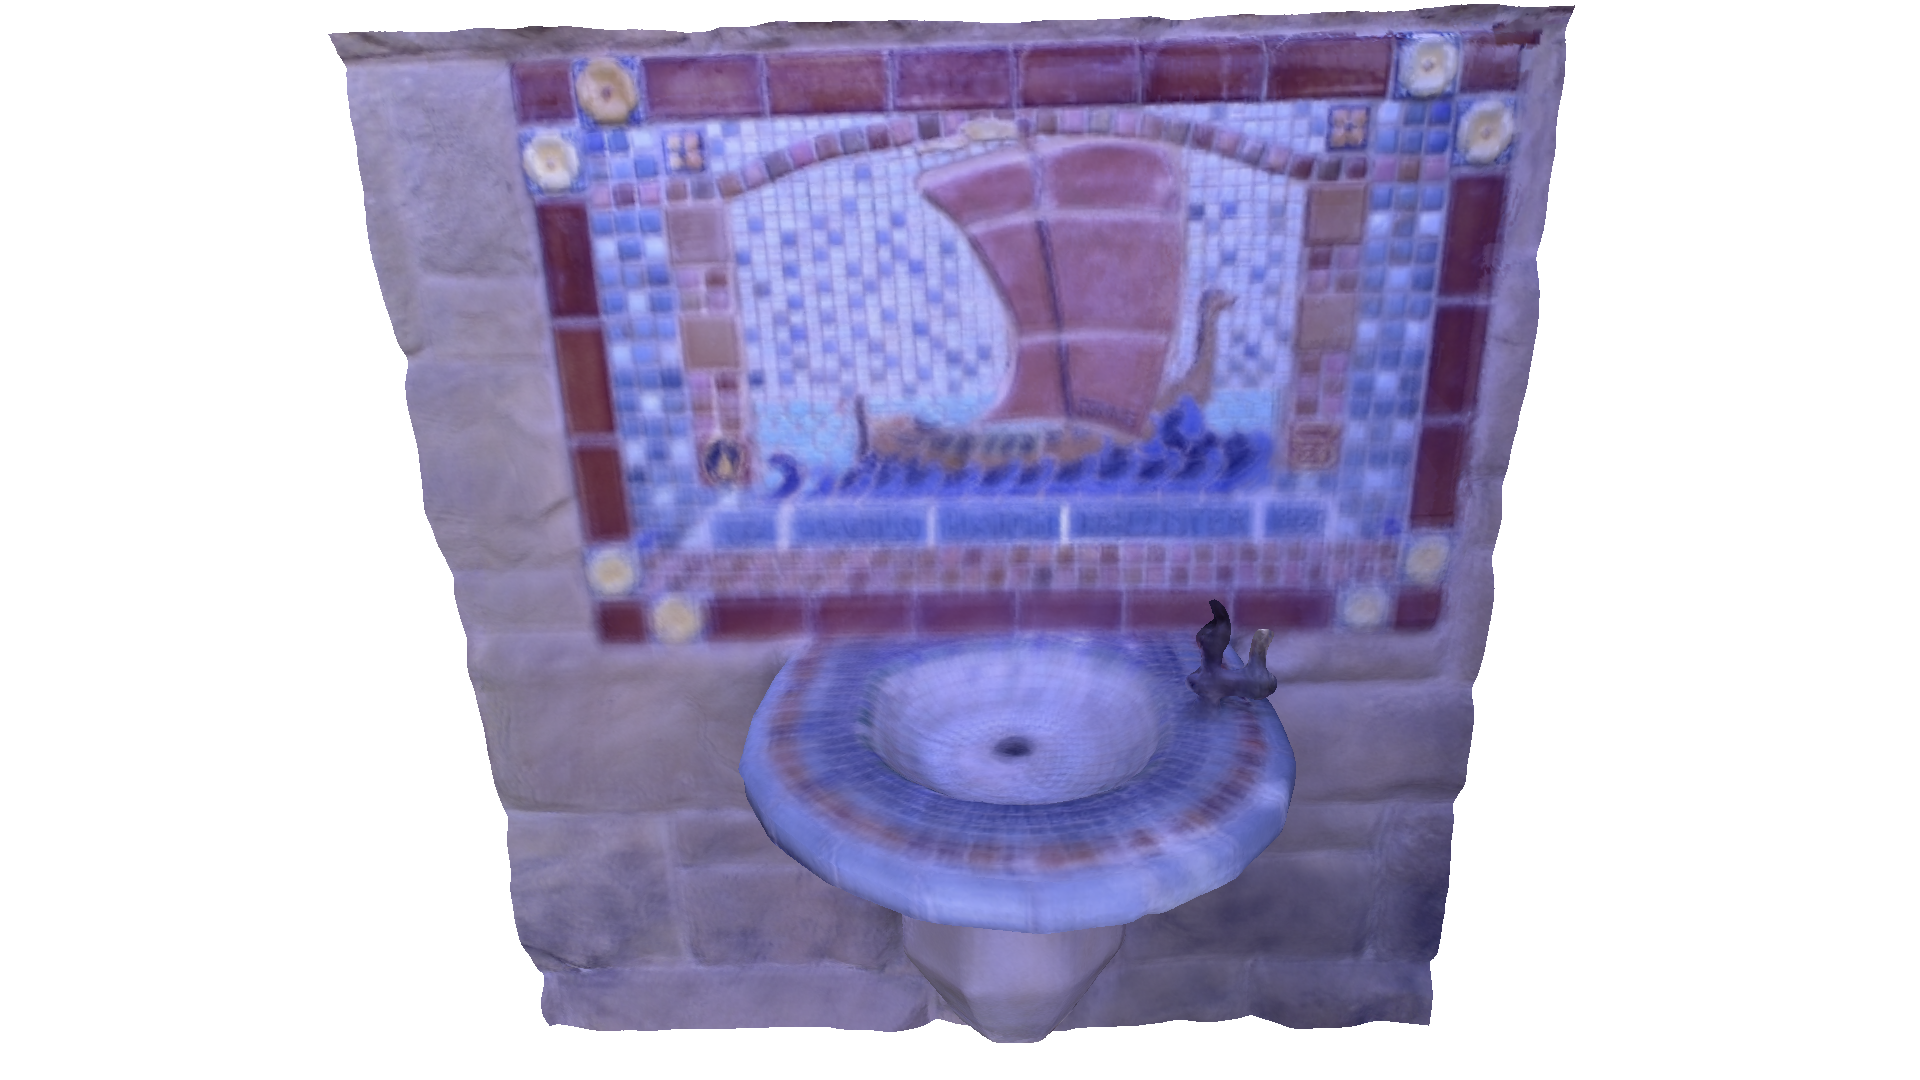

In [4]:
# Before full optimization, let's visualize texture map
# with given geometry, RGBD images, and camera poses.
mesh, camera_trajectory = cv3d.pipelines.color_map.run_rigid_optimizer(
    mesh, rgbd_images, camera_trajectory,
    cv3d.pipelines.color_map.RigidOptimizerOption(maximum_iteration=0))
cv3d.visualization.draw_geometries([mesh],
                                   zoom=0.5399,
                                   front=[0.0665, -0.1107, -0.9916],
                                   lookat=[0.7353, 0.6537, 1.0521],
                                   up=[0.0136, -0.9936, 0.1118])

## Rigid Optimization
The next step is to optimize camera poses to get a sharp color map.

The code below sets `maximum_iteration = 300` for actual iterations.

[CloudViewer DEBUG] [ColorMapOptimization] CreateUtilImagesFromRGBD
[CloudViewer DEBUG] [ColorMapOptimization] CreateDepthBoundaryMasks
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 0/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 1/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 2/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 3/33


[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 4/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 5/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 6/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 7/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 8/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 9/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 10/33


[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 11/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 12/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 13/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 14/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 15/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 16/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 17/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 18/33


[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 19/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 20/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 21/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 22/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 23/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 24/33


[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 25/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 26/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 27/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 28/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 29/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 30/33


[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 31/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 32/33
[CloudViewer DEBUG] [ColorMapOptimization] CreateVertexAndImageVisibility


... (35 outputs left out)

[CloudViewer DEBUG] Residual error : 9464.696972 (avg : 0.002012)
[CloudViewer DEBUG] [Iteration 0093] 
[CloudViewer DEBUG] Residual error : 9453.515185 (avg : 0.002009)
[CloudViewer DEBUG] [Iteration 0094] 
[CloudViewer DEBUG] Residual error : 9442.825386 (avg : 0.002007)
[CloudViewer DEBUG] [Iteration 0095] 
[CloudViewer DEBUG] Residual error : 9432.423517 (avg : 0.002005)


[CloudViewer DEBUG] [Iteration 0096] 
[CloudViewer DEBUG] Residual error : 9422.587274 (avg : 0.002003)
[CloudViewer DEBUG] [Iteration 0097] 
[CloudViewer DEBUG] Residual error : 9413.130207 (avg : 0.002001)
[CloudViewer DEBUG] [Iteration 0098] 
[CloudViewer DEBUG] Residual error : 9404.124481 (avg : 0.001999)


[CloudViewer DEBUG] [Iteration 0099] 
[CloudViewer DEBUG] Residual error : 9395.318127 (avg : 0.001997)
[CloudViewer DEBUG] [Iteration 0100] 
[CloudViewer DEBUG] Residual error : 9386.564204 (avg : 0.001995)
[CloudViewer DEBUG] [ColorMapOptimization] Set Mesh Color
[CloudViewer DEBUG] [RemoveDuplicatedVertices] 0 vertices have been removed.
[CloudViewer DEBUG] [RemoveDuplicatedTriangles] 0 triangles have been removed.


[CloudViewer DEBUG] [RemoveUnreferencedVertices] 734 vertices have been removed.
[CloudViewer DEBUG] [RemoveDegenerateTriangles] 0 triangles have been removed.
[CloudViewer DEBUG] Triangle mesh sampled from 536872 vertices and 1033745 triangles to 504121 vertices and 976218 triangles.
[CloudViewer WARNING] GLFW initialized for headless rendering.


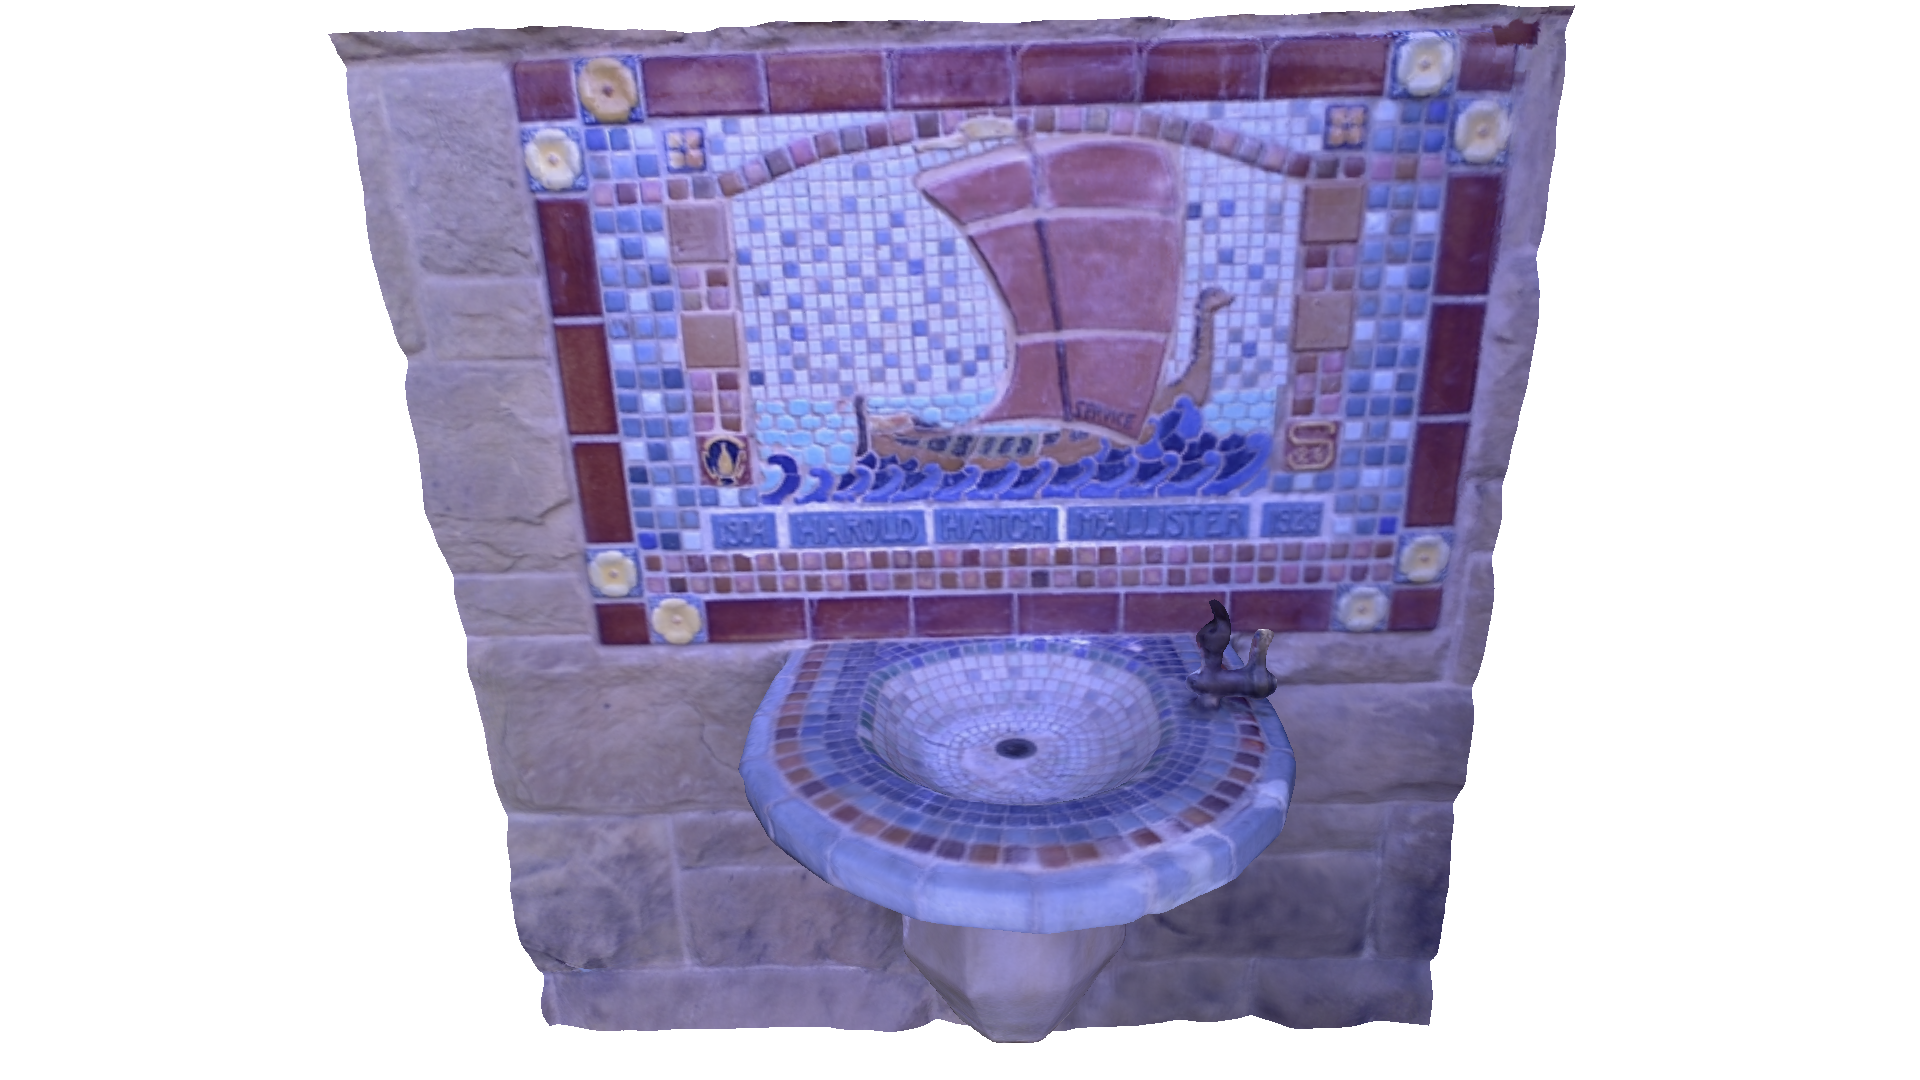

In [5]:
# Optimize texture and save the mesh as texture_mapped.ply
# This is implementation of following paper
# Q.-Y. Zhou and V. Koltun,
# Color Map Optimization for 3D Reconstruction with Consumer Depth Cameras,
# SIGGRAPH 2014

# Run rigid optimization.
maximum_iteration = 100 if is_ci else 300
with cv3d.utility.VerbosityContextManager(
        cv3d.utility.VerbosityLevel.Debug) as cm:
    mesh, camera_trajectory = cv3d.pipelines.color_map.run_rigid_optimizer(
        mesh, rgbd_images, camera_trajectory,
        cv3d.pipelines.color_map.RigidOptimizerOption(
            maximum_iteration=maximum_iteration))

cv3d.visualization.draw_geometries([mesh],
                                   zoom=0.5399,
                                   front=[0.0665, -0.1107, -0.9916],
                                   lookat=[0.7353, 0.6537, 1.0521],
                                   up=[0.0136, -0.9936, 0.1118])

The residual error implies inconsistency of image intensities. Lower residual leads to a better color map quality. By default, `ColorMapOptimizationOption` enables rigid optimization. It optimizes 6-dimensional pose of every cameras.

## Non-rigid Optimization
For better alignment quality, there is an option for non-rigid optimization. To enable this option, simply set `option.non_rigid_camera_coordinate` to `True` before calling `color_map_optimization`. Besides 6-dimensional camera poses, non-rigid optimization even considers local image warping represented by anchor points. This adds even more flexibility and leads to an even higher quality color mapping. The residual error is smaller than the case of rigid optimization.

In [6]:
# Run non-rigid optimization.
maximum_iteration = 100 if is_ci else 300
with cv3d.utility.VerbosityContextManager(
        cv3d.utility.VerbosityLevel.Debug) as cm:
    mesh, camera_trajectory = cv3d.pipelines.color_map.run_non_rigid_optimizer(
        mesh, rgbd_images, camera_trajectory,
        cv3d.pipelines.color_map.NonRigidOptimizerOption(
            maximum_iteration=maximum_iteration))

[CloudViewer DEBUG] [ColorMapOptimization] CreateUtilImagesFromRGBD
[CloudViewer DEBUG] [ColorMapOptimization] CreateDepthBoundaryMasks
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 0/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 1/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 2/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 3/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 4/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 5/33


[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 6/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 7/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 8/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 9/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 10/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 11/33


[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 12/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 13/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 14/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 15/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 16/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 17/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 18/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 19/33


[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 20/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 21/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 22/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 23/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 24/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 25/33


[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 26/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 27/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 28/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 29/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 30/33


[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 31/33
[CloudViewer DEBUG] [MakeDepthMasks] geometry::Image 32/33
[CloudViewer DEBUG] [ColorMapOptimization] CreateVertexAndImageVisibility
[CloudViewer DEBUG] [cam 0]: 249227/536872 (46.42205%) vertices are visible
[CloudViewer DEBUG] [cam 1]: 270723/536872 (50.42599%) vertices are visible
[CloudViewer DEBUG] [cam 2]: 230773/536872 (42.98473%) vertices are visible
[CloudViewer DEBUG] [cam 3]: 224391/536872 (41.79600%) vertices are visible
[CloudViewer DEBUG] [cam 4]: 212453/536872 (39.57237%) vertices are visible
[CloudViewer DEBUG] [cam 5]: 176854/536872 (32.94156%) vertices are visible
[CloudViewer DEBUG] [cam 6]: 194256/536872 (36.18293%) vertices are visible
[CloudViewer DEBUG] [cam 7]: 146473/536872 (27.28267%) vertices are visible
[CloudViewer DEBUG] [cam 8]: 149126/536872 (27.77683%) vertices are visible
[CloudViewer DEBUG] [cam 9]: 120544/536872 (22.45302%) vertices are visible
[CloudViewer DEBUG] [cam 10]: 159456/536872 (29.

... (45 outputs left out)

[CloudViewer DEBUG] [Iteration 0095] 
[CloudViewer DEBUG] Residual error : 6933.843502, reg : 1939.838771


[CloudViewer DEBUG] [Iteration 0096] 
[CloudViewer DEBUG] Residual error : 6928.335215, reg : 1948.237033
[CloudViewer DEBUG] [Iteration 0097] 
[CloudViewer DEBUG] Residual error : 6923.186785, reg : 1956.282267
[CloudViewer DEBUG] [Iteration 0098] 
[CloudViewer DEBUG] Residual error : 6917.679679, reg : 1964.501767
[CloudViewer DEBUG] [Iteration 0099] 


[CloudViewer DEBUG] Residual error : 6912.341878, reg : 1972.443931
[CloudViewer DEBUG] [Iteration 0100] 
[CloudViewer DEBUG] Residual error : 6907.042253, reg : 1980.497469
[CloudViewer DEBUG] [ColorMapOptimization] Set Mesh Color
[CloudViewer DEBUG] [RemoveDuplicatedVertices] 0 vertices have been removed.
[CloudViewer DEBUG] [RemoveDuplicatedTriangles] 0 triangles have been removed.
[CloudViewer DEBUG] [RemoveUnreferencedVertices] 768 vertices have been removed.


[CloudViewer DEBUG] [RemoveDegenerateTriangles] 0 triangles have been removed.
[CloudViewer DEBUG] Triangle mesh sampled from 536872 vertices and 1033745 triangles to 509770 vertices and 984365 triangles.


[CloudViewer WARNING] GLFW initialized for headless rendering.


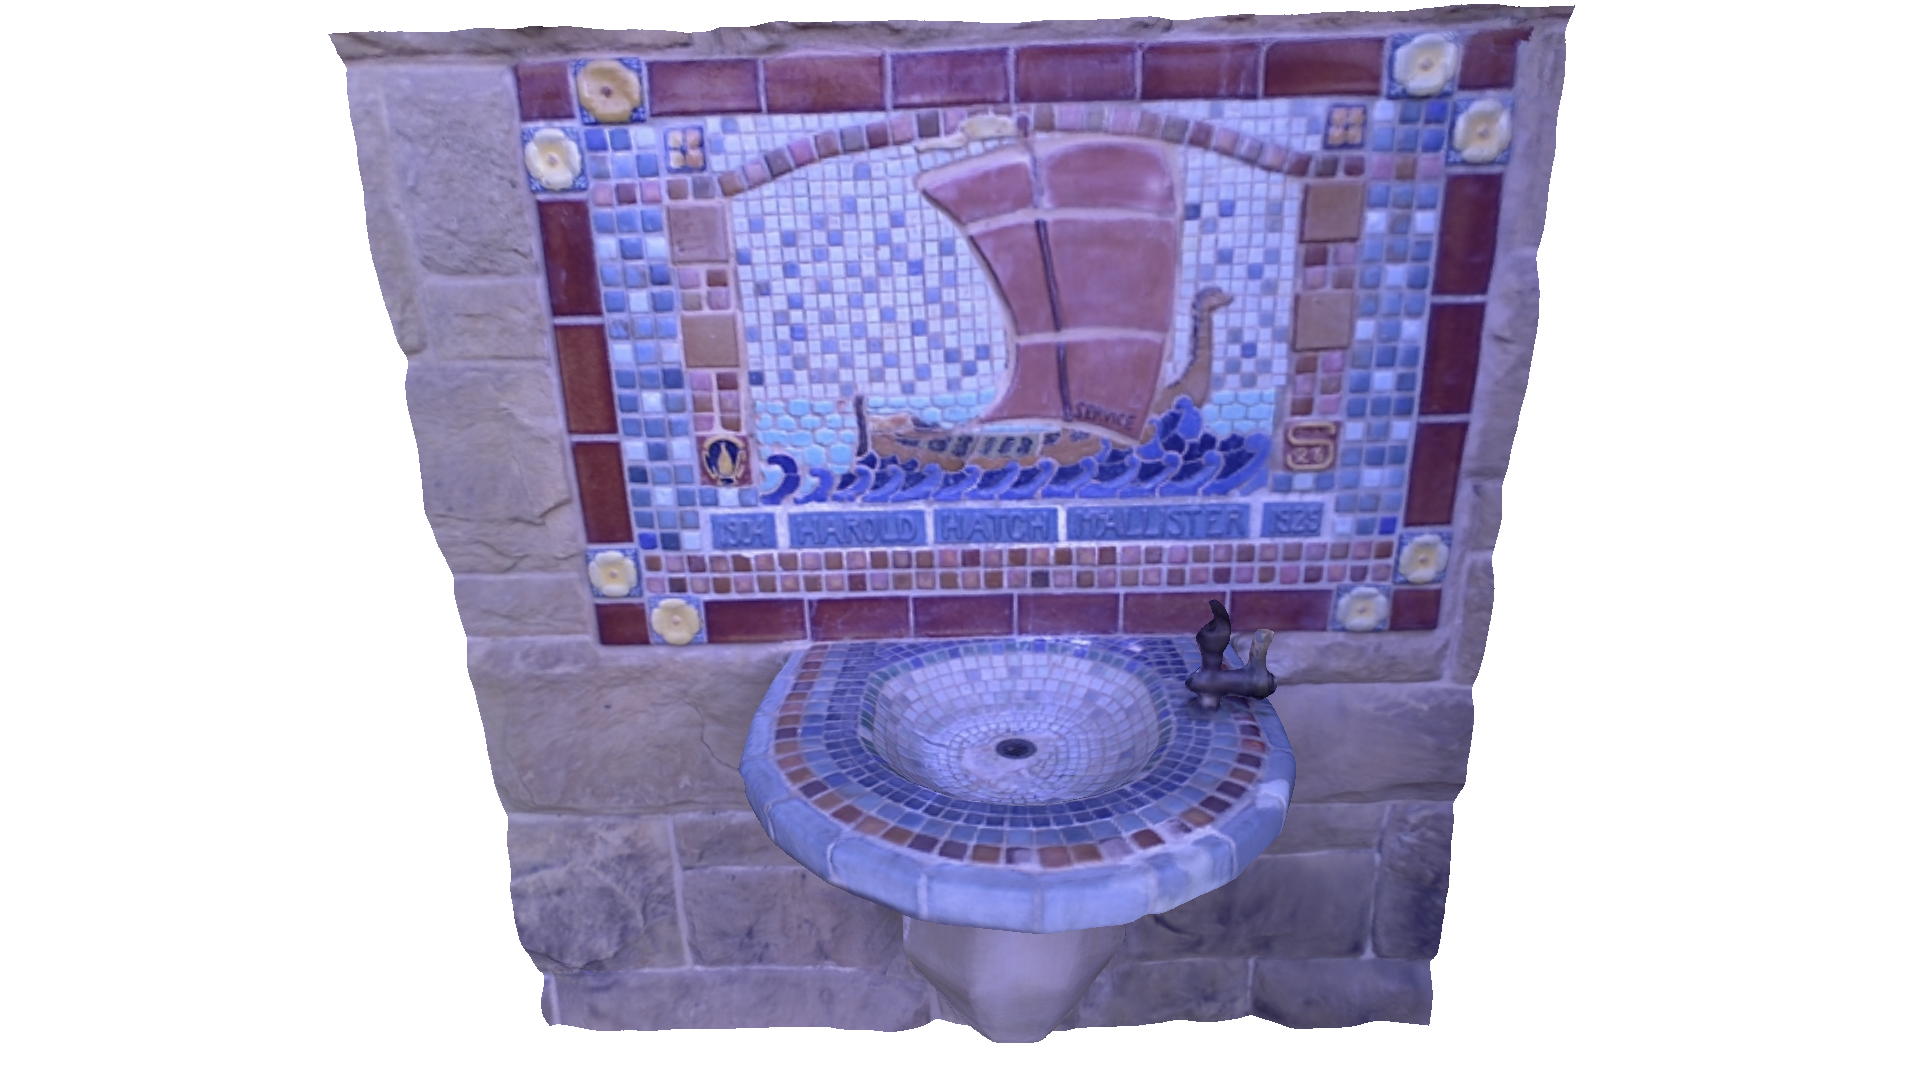

In [7]:
cv3d.visualization.draw_geometries([mesh],
                                   zoom=0.5399,
                                   front=[0.0665, -0.1107, -0.9916],
                                   lookat=[0.7353, 0.6537, 1.0521],
                                   up=[0.0136, -0.9936, 0.1118])